<h2>Import libraries </h2>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import warnings
warnings.filterwarnings("ignore")

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


<h2> Load dataset </h2>

In [3]:
url = "https://raw.githubusercontent.com/praveen-kumar-maurya/Superstore-Sales-Dashboard-Power-BI/main/Sample%20-%20Superstore.csv"

df = pd.read_csv(url, encoding="latin1")

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

df.head()

Dataset loaded successfully!
Shape of dataset: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,06-12-2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


<h2> dataset information </h2>

In [4]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape:
(9994, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Post

<h2> statical summary </h2>

In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,9994.0,NaN,NaN,NaN,4997.5,2885.163629,1.0,2499.25,4997.5,7495.75,9994.0
Order ID,9994,5009,CA-2017-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,1237,09-05-2016,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9994,1334,12/16/2015,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<h2> Missing Values </h2>

In [6]:
missing_values = df.isnull().sum()

print("Missing Values:")
display(missing_values[missing_values > 0])

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:


Series([], dtype: int64)


Total Missing Values: 0


<h2> duplicate records </h2>

In [7]:
duplicates = df.duplicated().sum()

print("Duplicate rows:", duplicates)

Duplicate rows: 0


<h2> Data Cleaning </h2>

In [9]:
# Cell 7 — Data Cleaning

# Convert date columns automatically
df["Order Date"] = pd.to_datetime(df["Order Date"], format="mixed")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="mixed")

# Remove duplicate rows
df = df.drop_duplicates()

# Remove rows with missing important values
df = df.dropna(subset=["Order Date", "Sales", "Profit", "Category"])

print("Data cleaning completed successfully!")
print("New dataset shape:", df.shape)

# Check date range
print("\nOrder Date Range:")
print(df["Order Date"].min(), "to", df["Order Date"].max())

Data cleaning completed successfully!
New dataset shape: (9994, 21)

Order Date Range:
2014-01-03 00:00:00 to 2017-12-30 00:00:00


<h2> Feature Engineering </h2>

In [10]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month_Name"] = df["Order Date"].dt.strftime("%b")
df["Year_Month"] = df["Order Date"].dt.to_period("M").astype(str)

# Profit margin
df["Profit_Margin"] = (df["Profit"] / df["Sales"]) * 100

# Shipping duration
df["Shipping_Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sales,Quantity,Discount,Profit,Year,Month,Month_Name,Year_Month,Profit_Margin,Shipping_Days
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,261.9600,2,0.00,41.9136,2016,11,Nov,2016-11,16.00,3
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,731.9400,3,0.00,219.5820,2016,11,Nov,2016-11,30.00,3
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,14.6200,2,0.00,6.8714,2016,6,Jun,2016-06,47.00,4
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,957.5775,5,0.45,-383.0310,2015,10,Oct,2015-10,-40.00,7
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,22.3680,2,0.20,2.5164,2015,10,Oct,2015-10,11.25,7


<h2> Basic KPI's </h2>

In [11]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
profit_margin = (total_profit / total_sales) * 100

print("===== KEY PERFORMANCE INDICATORS =====")
print(f"Total Sales      : ${total_sales:,.2f}")
print(f"Total Profit     : ${total_profit:,.2f}")
print(f"Total Orders     : {total_orders:,}")
print(f"Total Customers  : {total_customers:,}")
print(f"Profit Margin    : {profit_margin:.2f}%")

===== KEY PERFORMANCE INDICATORS =====
Total Sales      : $2,297,200.86
Total Profit     : $286,397.02
Total Orders     : 5,009
Total Customers  : 793
Profit Margin    : 12.47%


<h2> Visualisation1 : Monthly sales and profit trend </h2>

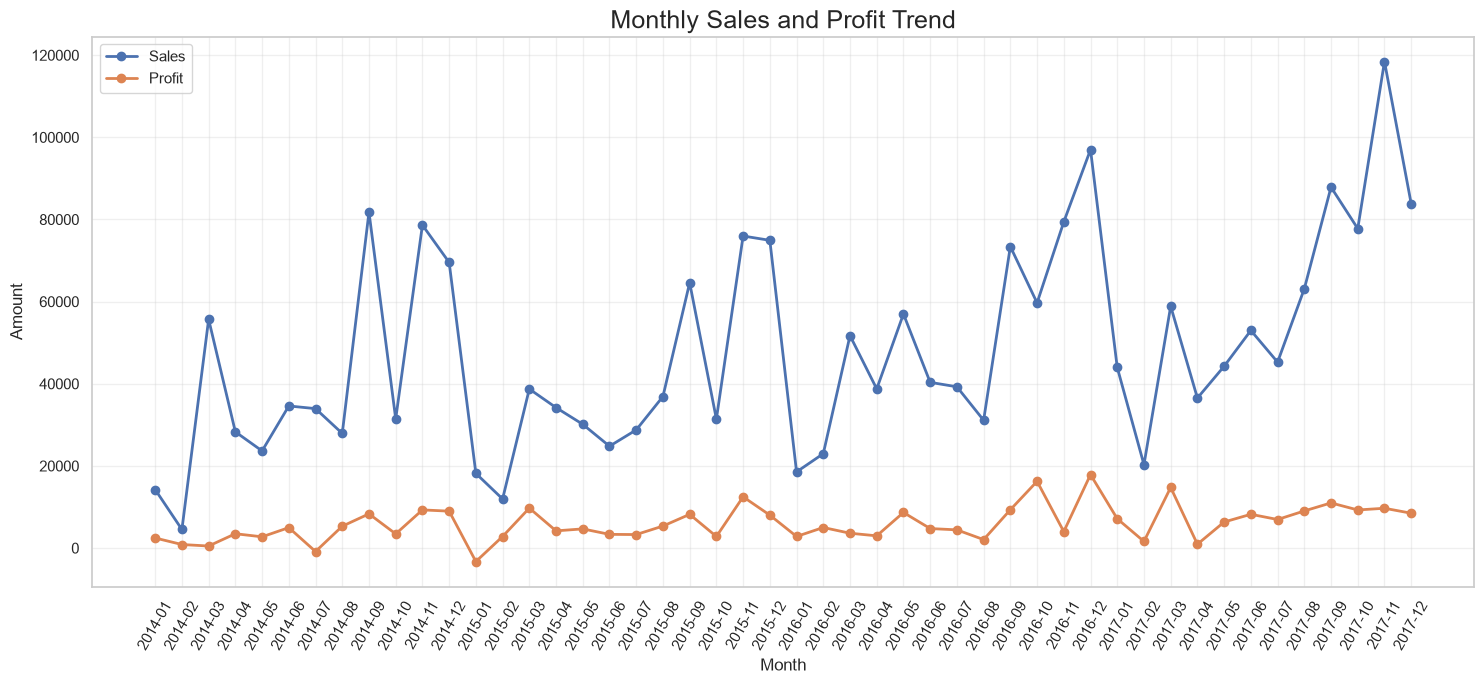

In [12]:
# Cell 10 — Monthly Sales & Profit Trend

monthly_data = (
    df.groupby("Year_Month")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum")
      )
      .reset_index()
)

plt.figure(figsize=(15, 7))

plt.plot(
    monthly_data["Year_Month"],
    monthly_data["Sales"],
    marker="o",
    linewidth=2,
    label="Sales"
)

plt.plot(
    monthly_data["Year_Month"],
    monthly_data["Profit"],
    marker="o",
    linewidth=2,
    label="Profit"
)

plt.title("Monthly Sales and Profit Trend", fontsize=18)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Amount", fontsize=12)

plt.xticks(rotation=60)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

<h2> Highest month of sales and profit </h2>

In [13]:
# Cell 11 — Find highest and lowest performing months

highest_sales_month = monthly_data.loc[
    monthly_data["Sales"].idxmax()
]

highest_profit_month = monthly_data.loc[
    monthly_data["Profit"].idxmax()
]

lowest_profit_month = monthly_data.loc[
    monthly_data["Profit"].idxmin()
]

print("Highest Sales Month:")
print(highest_sales_month)

print("\nHighest Profit Month:")
print(highest_profit_month)

print("\nLowest Profit Month:")
print(lowest_profit_month)

Highest Sales Month:
Year_Month       2017-11
Sales         118447.825
Profit         9690.1037
Name: 46, dtype: object

Highest Profit Month:
Year_Month       2016-12
Sales          96999.043
Profit        17885.3093
Name: 35, dtype: object

Lowest Profit Month:
Year_Month       2015-01
Sales         18174.0756
Profit         -3281.007
Name: 12, dtype: object


<h2> Visualisation 2 ; Category wise sales

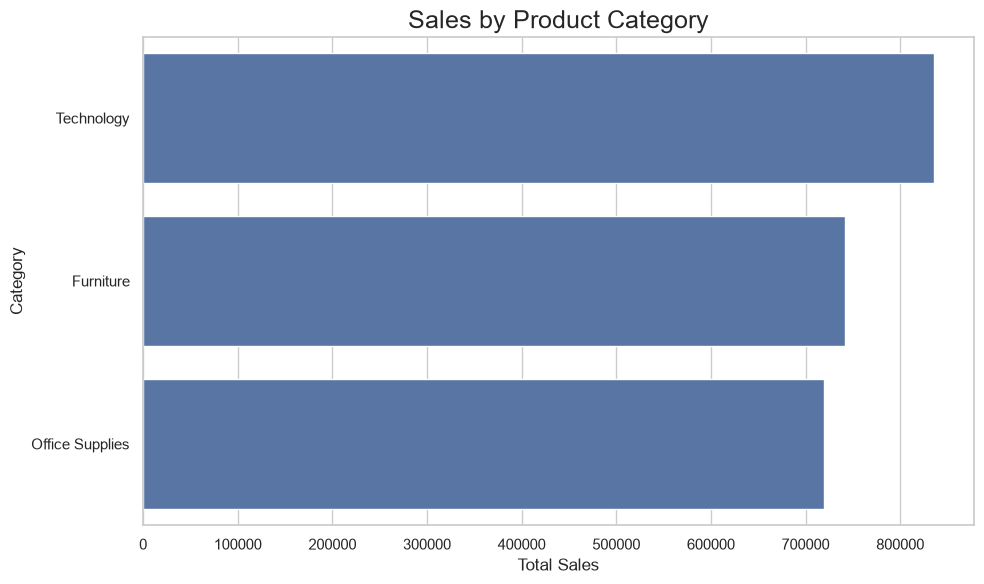

In [14]:
# Cell 12 — Category-wise Sales

category_sales = (
    df.groupby("Category")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_sales.values,
    y=category_sales.index
)

plt.title("Sales by Product Category", fontsize=18)
plt.xlabel("Total Sales")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

<h2> Category wise Profit </h2>

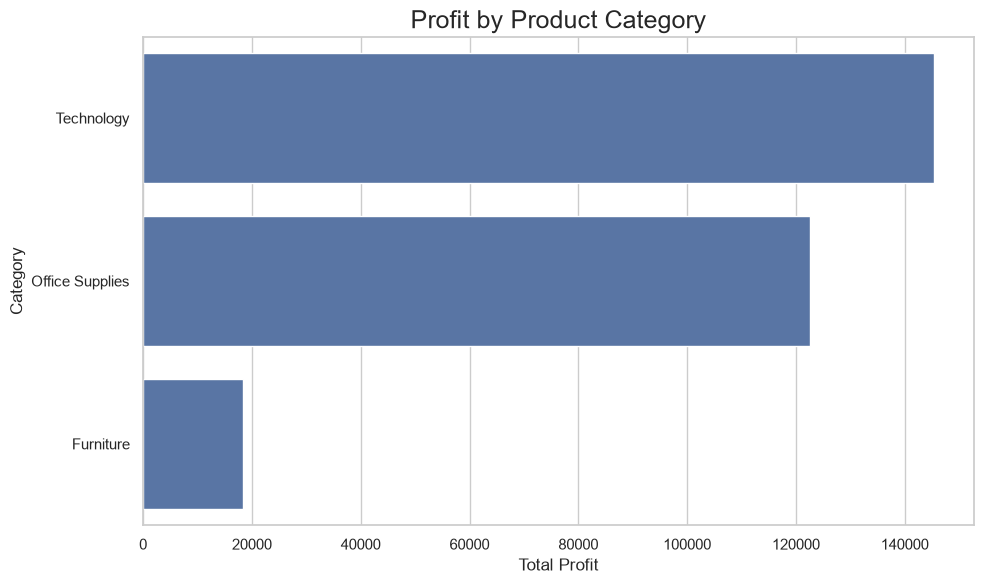

In [15]:
# Cell 13 — Category-wise Profit

category_profit = (
    df.groupby("Category")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_profit.values,
    y=category_profit.index
)

plt.title("Profit by Product Category", fontsize=18)
plt.xlabel("Total Profit")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

<h2> sales vs profit by category </h2>

In [16]:
# Cell 14 — Sales vs Profit

category_summary = (
    df.groupby("Category")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum")
      )
      .reset_index()
)

category_summary

,Category,Sales,Profit
0,Furniture,741999.7953,18451.2728
1,Office Supplies,719047.0320,122490.8008
2,Technology,836154.0330,145454.9481


<h2> Visualisation 3 : Region X Category heatmap </h2>

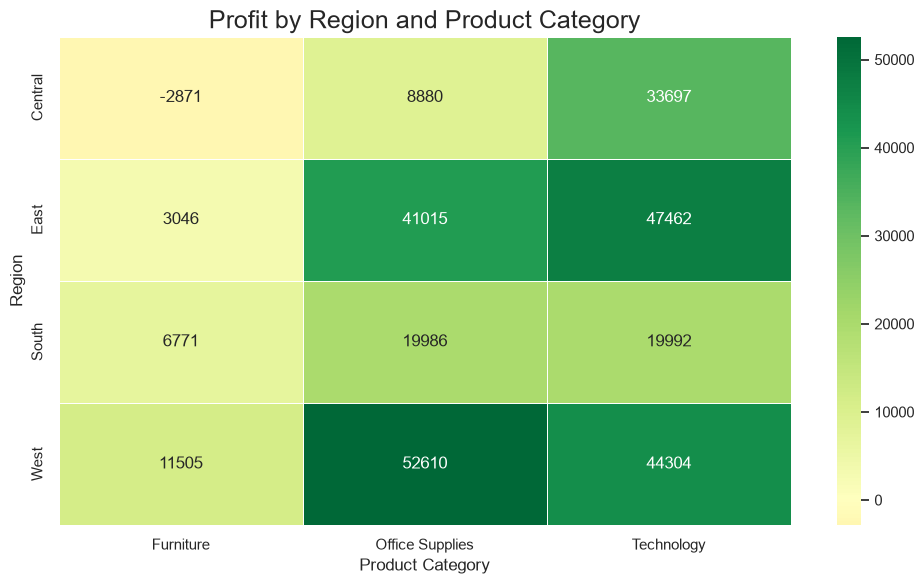

In [17]:
# Cell 15 — Region × Category Profit Heatmap

region_category_profit = pd.pivot_table(
    df,
    values="Profit",
    index="Region",
    columns="Category",
    aggfunc="sum"
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    region_category_profit,
    annot=True,
    fmt=".0f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5
)

plt.title("Profit by Region and Product Category", fontsize=18)
plt.xlabel("Product Category")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

<h2> Highest lowest combination </h2>

In [18]:
# Cell 16 — Highest and Lowest Region-Category Profit

profit_combinations = region_category_profit.stack().reset_index()

profit_combinations.columns = [
    "Region",
    "Category",
    "Profit"
]

highest_combination = profit_combinations.loc[
    profit_combinations["Profit"].idxmax()
]

lowest_combination = profit_combinations.loc[
    profit_combinations["Profit"].idxmin()
]

print("Highest Profit Combination:")
print(highest_combination)

print("\nLowest Profit Combination:")
print(lowest_combination)

Highest Profit Combination:
Region                 West
Category    Office Supplies
Profit            52609.849
Name: 10, dtype: object

Lowest Profit Combination:
Region        Central
Category    Furniture
Profit     -2871.0494
Name: 0, dtype: object


<h2> Visuatisation4 : discount vs profit </h2>

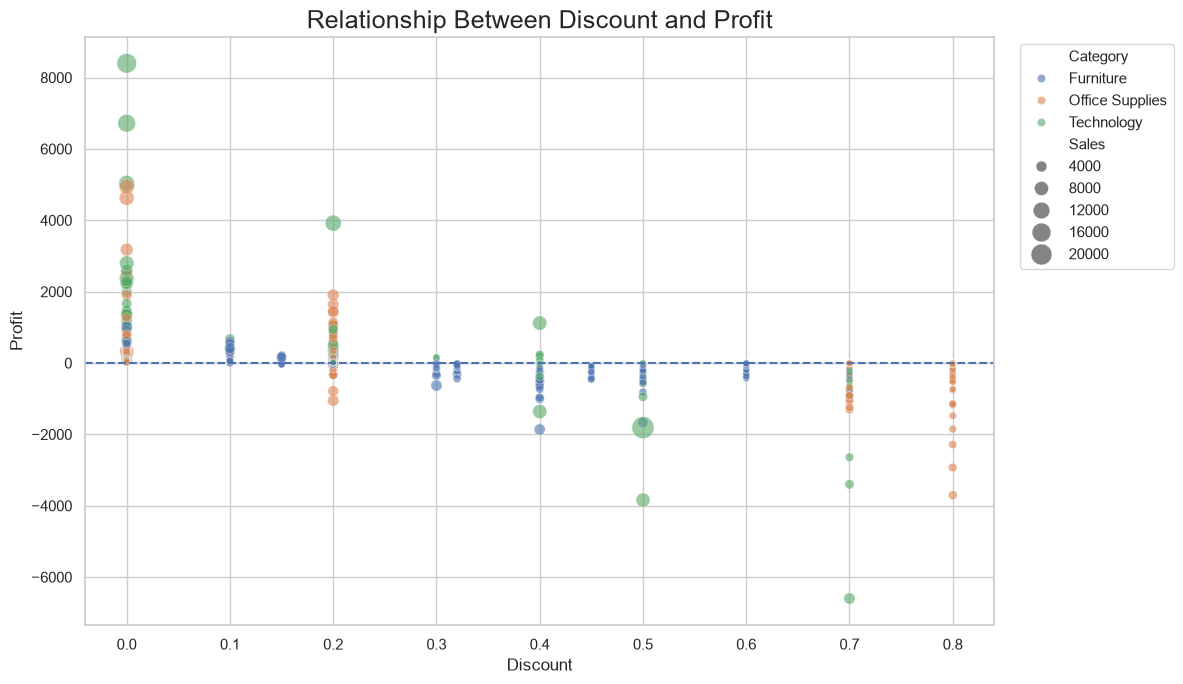

In [19]:
# Cell 17 — Discount vs Profit Scatter Plot

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    hue="Category",
    size="Sales",
    sizes=(20, 250),
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1.5
)

plt.title("Relationship Between Discount and Profit", fontsize=18)
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

<h2> profit analysis of discount groups </h2>

In [21]:
# Cell 18 — Discount Level Analysis

df["Discount_Level"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0, 0.10, 0.20, 0.30, 0.50, 1],
    labels=[
        "0%",
        "1-10%",
        "11-20%",
        "21-30%",
        "31-50%",
        "50%+"
    ]
)

discount_analysis = (
    df.groupby("Discount_Level", observed=False)
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "count")
      )
      .reset_index()
)

discount_analysis

,Discount_Level,Sales,Profit,Orders
0,0%,1.087908e+06,320987.6032,4798
1,1-10%,5.436935e+04,9029.1770,94
2,11-20%,7.921529e+05,91756.2975,3709
3,21-30%,1.032267e+05,-10369.2774,227
4,31-50%,1.953148e+05,-48447.7273,310
5,50%+,6.422874e+04,-76559.0513,856


<h2> discount vs average  profit </h2>

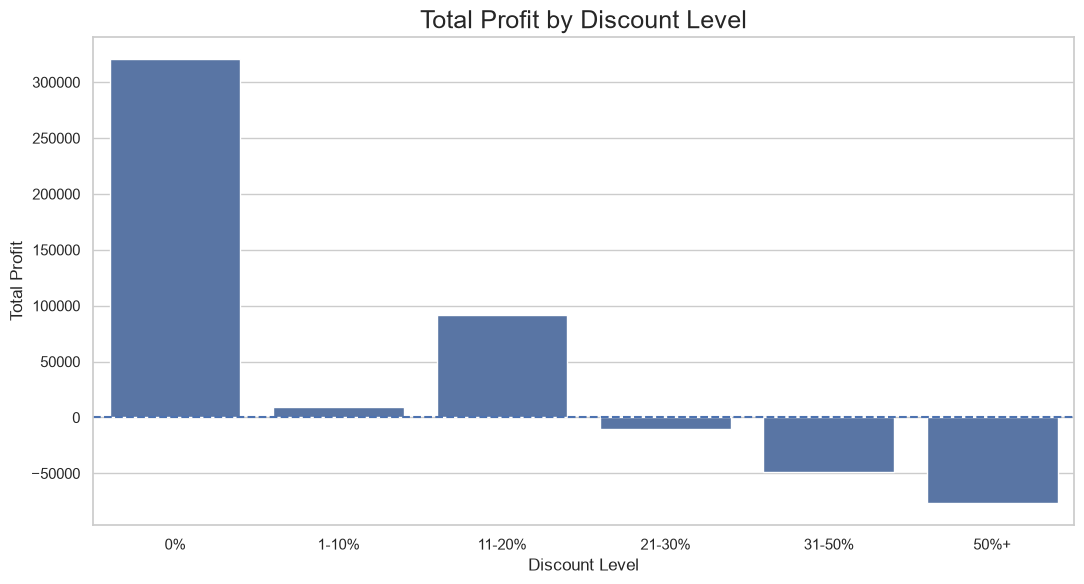

In [22]:
# Cell 19 — Average Profit by Discount Level

plt.figure(figsize=(11, 6))

sns.barplot(
    data=discount_analysis,
    x="Discount_Level",
    y="Profit"
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1.5
)

plt.title("Total Profit by Discount Level", fontsize=18)
plt.xlabel("Discount Level")
plt.ylabel("Total Profit")

plt.tight_layout()
plt.show()

<h2> Profit distribution by category </h2>

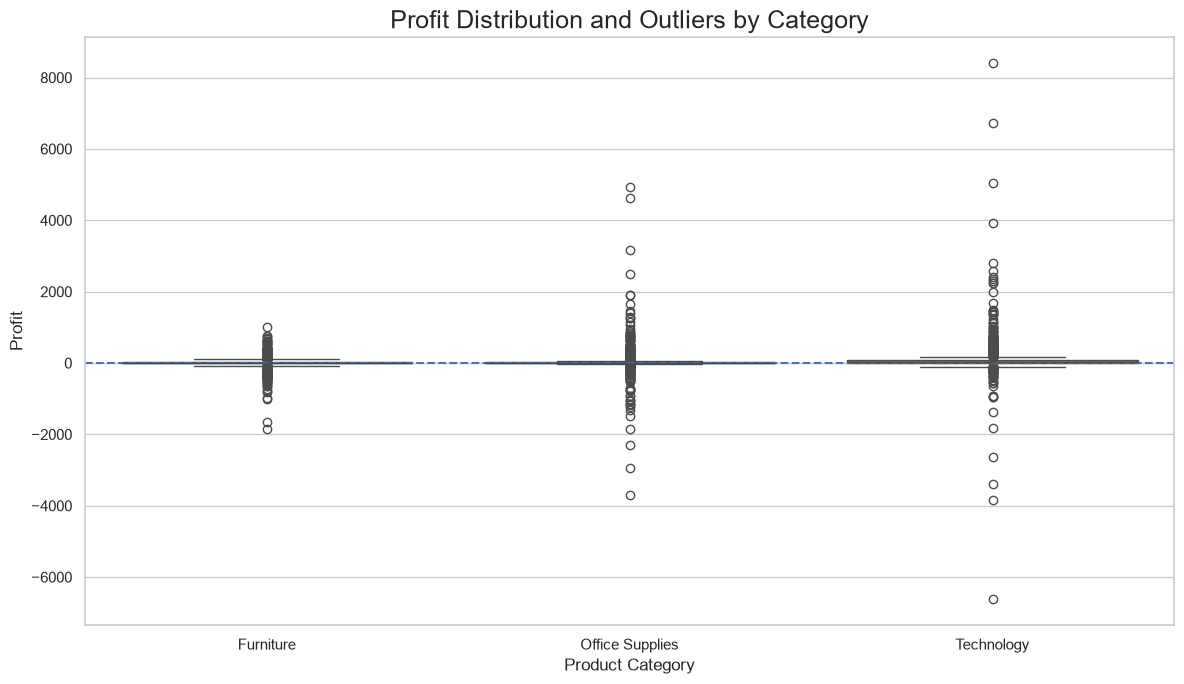

In [23]:
# Cell 20 — Profit Distribution Box Plot

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    x="Category",
    y="Profit"
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1.5
)

plt.title(
    "Profit Distribution and Outliers by Category",
    fontsize=18
)

plt.xlabel("Product Category")
plt.ylabel("Profit")

plt.tight_layout()
plt.show()

<h2> Loss making order identification </h2>

In [24]:
# Cell 21 — Loss-Making Orders

loss_orders = df[df["Profit"] < 0]

print("Total loss-making records:", len(loss_orders))

print(
    "Total loss amount:",
    f"${loss_orders['Profit'].sum():,.2f}"
)

display(
    loss_orders[
        [
            "Order ID",
            "Product Name",
            "Category",
            "Sub-Category",
            "Sales",
            "Discount",
            "Profit"
        ]
    ].sort_values("Profit").head(10)
)

Total loss-making records: 1871
Total loss amount: $-156,131.29


,Order ID,Product Name,Category,Sub-Category,Sales,Discount,Profit
7772,CA-2016-108196,Cubify CubeX 3D Printer Double Head Print,Technology,Machines,4499.985,0.7,-6599.9780
683,US-2017-168116,Cubify CubeX 3D Printer Triple Head Print,Technology,Machines,7999.980,0.5,-3839.9904
9774,CA-2014-169019,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,2177.584,0.8,-3701.8928
3011,CA-2017-134845,Lexmark MX611dhe Monochrome Laser Printer,Technology,Machines,2549.985,0.7,-3399.9800
4991,US-2017-122714,Ibico EPK-21 Electric Binding System,Office Supplies,Binders,1889.990,0.8,-2929.4845
3151,CA-2015-147830,Cubify CubeX 3D Printer Double Head Print,Technology,Machines,1799.994,0.7,-2639.9912
5310,CA-2017-131254,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,Binders,1525.188,0.8,-2287.7820
9639,CA-2015-116638,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,Tables,4297.644,0.4,-1862.3124
1199,CA-2016-130946,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,1088.792,0.8,-1850.9464
2697,CA-2014-145317,Cisco TelePresence System EX90 Videoconferenci...,Technology,Machines,22638.480,0.5,-1811.0784


<h2> Top 10 Most Profitable Sub-Categories </h2>

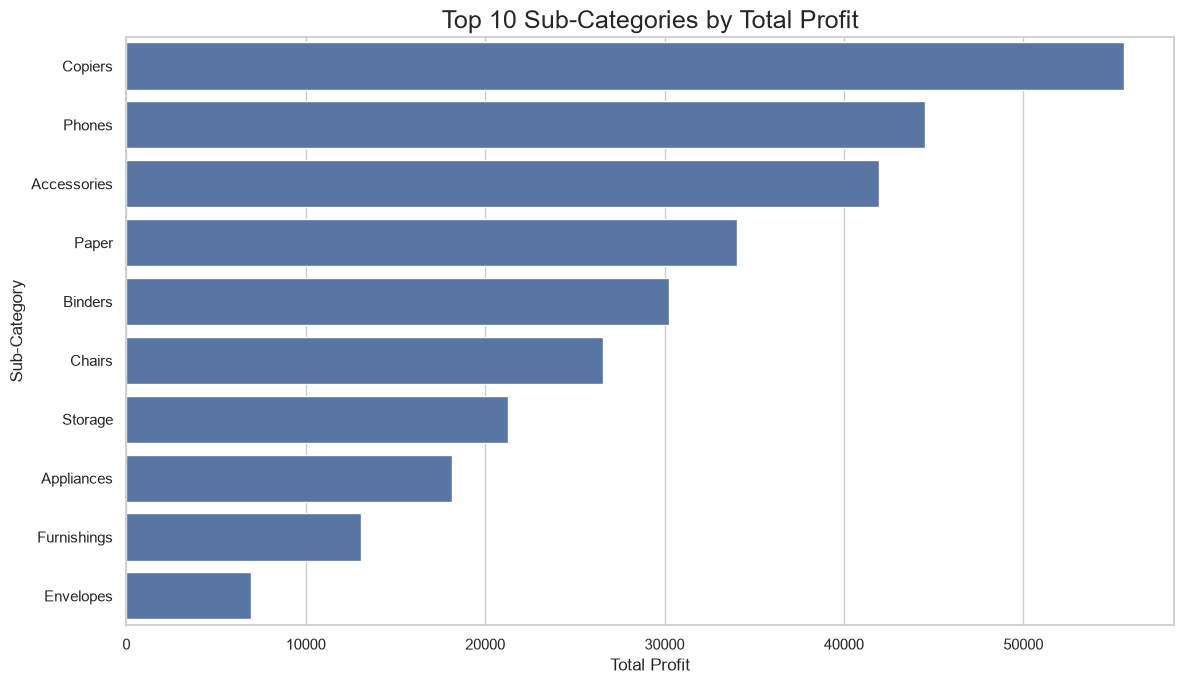

In [25]:
# Cell 22 — Top 10 Sub-Categories by Profit

subcat_profit = (
    df.groupby("Sub-Category")["Profit"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=subcat_profit.values,
    y=subcat_profit.index
)

plt.title(
    "Top 10 Sub-Categories by Total Profit",
    fontsize=18
)

plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")

plt.tight_layout()
plt.show()

<h2> Bottom 10 subcategores </h2>

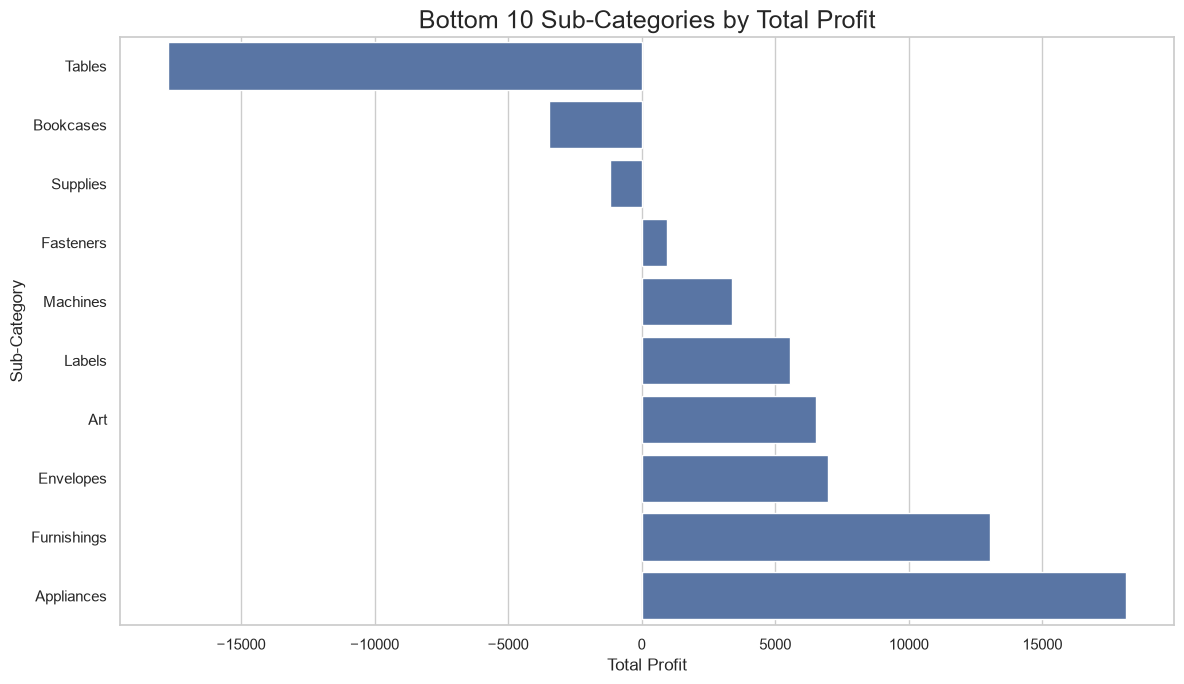

In [26]:
# Cell 23 — Bottom 10 Sub-Categories by Profit

bottom_subcat = (
    df.groupby("Sub-Category")["Profit"]
      .sum()
      .sort_values(ascending=True)
      .head(10)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=bottom_subcat.values,
    y=bottom_subcat.index
)

plt.title(
    "Bottom 10 Sub-Categories by Total Profit",
    fontsize=18
)

plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")

plt.tight_layout()
plt.show()

<h2> Interactive Regional Sales & Profit <h2>

In [27]:
# Cell 24 — Interactive Regional Sales & Profit Visualization

regional_data = (
    df.groupby("Region")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique")
      )
      .reset_index()
)

regional_data

,Region,Sales,Profit,Orders
0,Central,501239.8908,39706.3625,1175
1,East,678781.2400,91522.7800,1401
2,South,391721.9050,46749.4303,822
3,West,725457.8245,108418.4489,1611


<h2> Interactive Plotly Chart </h2>

In [28]:
# Cell 25 — Interactive Regional Performance

fig = px.bar(
    regional_data,
    x="Region",
    y="Sales",
    color="Profit",
    text="Sales",
    hover_data=[
        "Profit",
        "Orders"
    ],
    title="Interactive Regional Sales and Profit Analysis",
    color_continuous_scale="RdYlGn"
)

fig.update_traces(
    texttemplate="$%{text:,.0f}",
    textposition="outside"
)

fig.update_layout(
    xaxis_title="Region",
    yaxis_title="Total Sales",
    coloraxis_colorbar_title="Profit"
)

fig.show()

<h2> Interactive Category Performance </h2>

In [29]:
# Cell 26 — Interactive Category Performance

category_interactive = (
    df.groupby(["Category", "Sub-Category"])
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .reset_index()
)

fig = px.scatter(
    category_interactive,
    x="Sales",
    y="Profit",
    size="Quantity",
    color="Category",
    hover_name="Sub-Category",
    title="Sales vs Profit by Sub-Category",
    size_max=50
)

fig.add_hline(
    y=0,
    line_dash="dash"
)

fig.show()

<h2> save interactive chart </h2>

In [30]:
# Cell 27 — Save Plotly Visualization

fig.write_html(
    "interactive_sales_profit.html"
)

print("Interactive visualization saved successfully!")

Interactive visualization saved successfully!


<h2> overall business summary </h2>

In [31]:
# Cell 28 — Overall Business Summary

summary = {
    "Total Sales": df["Sales"].sum(),
    "Total Profit": df["Profit"].sum(),
    "Total Orders": df["Order ID"].nunique(),
    "Total Customers": df["Customer ID"].nunique(),
    "Total Quantity": df["Quantity"].sum(),
    "Average Order Value": df["Sales"].sum() / df["Order ID"].nunique(),
    "Overall Profit Margin (%)": (df["Profit"].sum() / df["Sales"].sum()) * 100
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
)

display(summary_df)

,Metric,Value
0,Total Sales,2.297201e+06
1,Total Profit,2.863970e+05
2,Total Orders,5.009000e+03
3,Total Customers,7.930000e+02
4,Total Quantity,3.787300e+04
5,Average Order Value,4.586147e+02
6,Overall Profit Margin (%),1.246722e+01


<h2> Best performing category </h2>

In [32]:
# Cell 29 — Best Performing Category

category_performance = (
    df.groupby("Category")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .reset_index()
)

category_performance["Profit_Margin"] = (
    category_performance["Profit"] /
    category_performance["Sales"] * 100
)

best_category = category_performance.loc[
    category_performance["Profit"].idxmax()
]

print("Best Performing Category")
print("------------------------")
print("Category:", best_category["Category"])
print(f"Sales: ${best_category['Sales']:,.2f}")
print(f"Profit: ${best_category['Profit']:,.2f}")
print(f"Profit Margin: {best_category['Profit_Margin']:.2f}%")

Best Performing Category
------------------------
Category: Technology
Sales: $836,154.03
Profit: $145,454.95
Profit Margin: 17.40%


<h2> Best & Worst Region </h2>

In [33]:
# Cell 30 — Regional Performance

region_performance = (
    df.groupby("Region")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique")
      )
      .reset_index()
)

region_performance["Profit_Margin"] = (
    region_performance["Profit"] /
    region_performance["Sales"] * 100
)

best_region = region_performance.loc[
    region_performance["Profit"].idxmax()
]

worst_region = region_performance.loc[
    region_performance["Profit"].idxmin()
]

print("Best Performing Region")
print("----------------------")
print(best_region)

print("\nLowest Profit Region")
print("--------------------")
print(worst_region)

Best Performing Region
----------------------
Region                  West
Sales            725457.8245
Profit           108418.4489
Orders                  1611
Profit_Margin      14.944831
Name: 3, dtype: object

Lowest Profit Region
--------------------
Region               Central
Sales            501239.8908
Profit            39706.3625
Orders                  1175
Profit_Margin       7.921629
Name: 0, dtype: object


<h2> Year wise growth </h2>

In [34]:
# Cell 32 — Year-wise Sales and Profit

yearly_performance = (
    df.groupby("Year")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum")
      )
      .reset_index()
)

yearly_performance["Sales_Growth_%"] = (
    yearly_performance["Sales"].pct_change() * 100
)

yearly_performance["Profit_Growth_%"] = (
    yearly_performance["Profit"].pct_change() * 100
)

display(yearly_performance)

,Year,Sales,Profit,Sales_Growth_%,Profit_Growth_%
0,2014,484247.4981,49543.9741,NaN,NaN
1,2015,470532.5090,61618.6037,-2.832227,24.371540
2,2016,609205.5980,81795.1743,29.471521,32.744284
3,2017,733215.2552,93439.2696,20.355962,14.235675


<h2> Top 10 products by profit </h2>

In [35]:
# Cell 33 — Top 10 Products by Profit

top_products = (
    df.groupby("Product Name")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum")
      )
      .sort_values("Profit", ascending=False)
      .head(10)
      .reset_index()
)

display(top_products)

,Product Name,Sales,Profit
0,Canon imageCLASS 2200 Advanced Copier,61599.824,25199.9280
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384,7753.0390
2,Hewlett Packard LaserJet 3310 Copier,18839.686,6983.8836
3,Canon PC1060 Personal Laser Copier,11619.834,4570.9347
4,HP Designjet T520 Inkjet Large Format Printer ...,18374.895,4094.9766
5,Ativa V4110MDD Micro-Cut Shredder,7699.890,3772.9461
6,"3D Systems Cube Printer, 2nd Generation, Magenta",14299.890,3717.9714
7,Plantronics Savi W720 Multi-Device Wireless He...,9367.290,3696.2820
8,Ibico EPK-21 Electric Binding System,15875.916,3345.2823
9,Zebra ZM400 Thermal Label Printer,6965.700,3343.5360


<h2> Final automated insights </h2>

In [37]:
# Cell 34 — Final Automated Insights

# Recalculate required summaries
category_performance = (
    df.groupby("Category")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .reset_index()
)

region_performance = (
    df.groupby("Region")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique")
      )
      .reset_index()
)

subcat_performance = (
    df.groupby("Sub-Category")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .reset_index()
)

# Find best/worst performers
best_category = category_performance.loc[
    category_performance["Profit"].idxmax()
]

best_region = region_performance.loc[
    region_performance["Profit"].idxmax()
]

worst_region = region_performance.loc[
    region_performance["Profit"].idxmin()
]

best_subcategory = subcat_performance.loc[
    subcat_performance["Profit"].idxmax()
]

worst_subcategory = subcat_performance.loc[
    subcat_performance["Profit"].idxmin()
]

# Loss-making records
loss_orders = df[df["Profit"] < 0]

# Monthly performance
monthly_data = (
    df.groupby("Year_Month")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum")
      )
      .reset_index()
)

highest_sales_month = monthly_data.loc[
    monthly_data["Sales"].idxmax()
]

highest_profit_month = monthly_data.loc[
    monthly_data["Profit"].idxmax()
]

# Overall metrics
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
profit_margin = (total_profit / total_sales) * 100

# Print final story
print("=" * 65)
print("FINAL DATA STORY")
print("=" * 65)

print(f"\n1. Total Sales: ${total_sales:,.2f}")

print(f"\n2. Total Profit: ${total_profit:,.2f}")

print(f"\n3. Overall Profit Margin: {profit_margin:.2f}%")

print(
    f"\n4. Highest-Profit Category: "
    f"{best_category['Category']}"
)

print(
    f"   Profit: ${best_category['Profit']:,.2f}"
)

print(
    f"\n5. Highest-Profit Region: "
    f"{best_region['Region']}"
)

print(
    f"   Profit: ${best_region['Profit']:,.2f}"
)

print(
    f"\n6. Lowest-Profit Region: "
    f"{worst_region['Region']}"
)

print(
    f"   Profit: ${worst_region['Profit']:,.2f}"
)

print(
    f"\n7. Most Profitable Sub-Category: "
    f"{best_subcategory['Sub-Category']}"
)

print(
    f"   Profit: ${best_subcategory['Profit']:,.2f}"
)

print(
    f"\n8. Lowest-Profit Sub-Category: "
    f"{worst_subcategory['Sub-Category']}"
)

print(
    f"   Profit: ${worst_subcategory['Profit']:,.2f}"
)

print(
    f"\n9. Highest-Sales Month: "
    f"{highest_sales_month['Year_Month']}"
)

print(
    f"   Sales: ${highest_sales_month['Sales']:,.2f}"
)

print(
    f"\n10. Highest-Profit Month: "
    f"{highest_profit_month['Year_Month']}"
)

print(
    f"    Profit: ${highest_profit_month['Profit']:,.2f}"
)

print(
    f"\n11. Loss-Making Records: "
    f"{len(loss_orders):,}"
)

print("\n" + "=" * 65)
print("Analysis completed successfully!")
print("=" * 65)

FINAL DATA STORY

1. Total Sales: $2,297,200.86

2. Total Profit: $286,397.02

3. Overall Profit Margin: 12.47%

4. Highest-Profit Category: Technology
   Profit: $145,454.95

5. Highest-Profit Region: West
   Profit: $108,418.45

6. Lowest-Profit Region: Central
   Profit: $39,706.36

7. Most Profitable Sub-Category: Copiers
   Profit: $55,617.82

8. Lowest-Profit Sub-Category: Tables
   Profit: $-17,725.48

9. Highest-Sales Month: 2017-11
   Sales: $118,447.82

10. Highest-Profit Month: 2016-12
    Profit: $17,885.31

11. Loss-Making Records: 1,871

Analysis completed successfully!


<h2> Correlation analysis </h2>

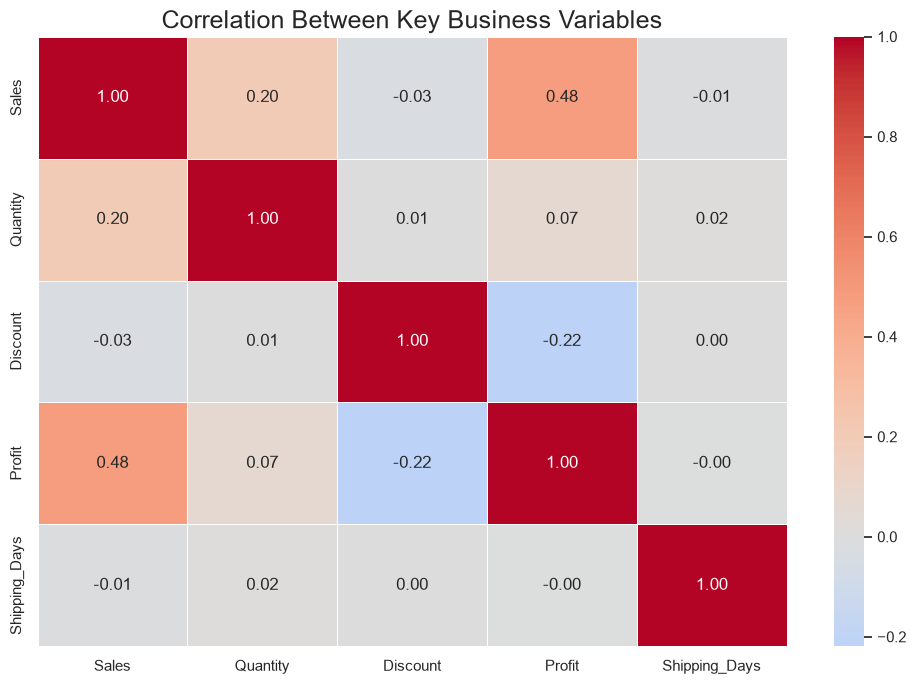

In [38]:
# Cell 35 — Correlation Analysis

correlation_data = df[
    ["Sales", "Quantity", "Discount", "Profit", "Shipping_Days"]
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_data,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title(
    "Correlation Between Key Business Variables",
    fontsize=18
)

plt.tight_layout()
plt.show()

<h2> Save important tables </h2>

In [39]:
# Cell 36 — Export Analytical Results

category_performance.to_csv(
    "category_performance.csv",
    index=False
)

region_performance.to_csv(
    "region_performance.csv",
    index=False
)

subcat_performance.to_csv(
    "subcategory_performance.csv",
    index=False
)

monthly_data.to_csv(
    "monthly_sales_profit.csv",
    index=False
)

print("Analytical tables exported successfully!")

Analytical tables exported successfully!
